# 04 · Reprodução do artigo e contribuição

**Artigo:** Gaul et al. (2025), *Underage Detection through a Multi-Task and MultiAge Approach for Screening Minors in Unconstrained Imagery*.

**Experimento principal reproduzido (escala reduzida):** FaRL congelado + MLP pequeno (MultiAge, arquitetura I-256) comparando
- **A · Só idade:** apenas a cabeça de idade (102 classes); a decisão de menoridade usa a idade estimada
- **B · Multi-task (artigo):** cabeça de idade + cabeças binárias de menoridade para 12, 15, 18 e 21 anos

**Contribuição:**
- **C · Multi-task + limiares legais:** acrescenta cabeças para **13 e 16 anos**, idades usadas em leis de proteção online
  (13 anos é a idade mínima usual de cadastro em redes sociais; 16 anos aparece no ECA Digital e na GDPR europeia como limite para consentimento)

**Métrica do artigo:** F2 no ponto de operação com recall de menores = 0,99 (taxa de falso adulto de 1%), limiar ajustado na validação.

### Diferenças em relação ao artigo (escala reduzida)
- Treino só com UTKFace (o artigo junta vários datasets no conjunto "Overall"), teste no UTKFace e no FG-NET
- Perda padrão do artigo (α = 1, γ = 0, sem age gap) com reamostragem balanceada por idade (Seção 4.2), que foi a melhor configuração reportada
- Mesmos splits do notebook 03, 3 sementes por configuração e intervalo de confiança de 95% por bootstrap pareado

## Hipóteses (escritas antes de rodar)

**H1 · Reprodução.** O modelo multi-task (B) tem F2 maior que o modelo só idade (A) no limiar de 18 anos, como no artigo
(que reporta F2 de 0,801 para 0,857). Motivo: a cabeça binária otimiza diretamente a separação no limiar, enquanto a idade estimada
carrega o erro de regressão (cerca de 4 a 5 anos) para a decisão.

**H2 · Contribuição.** Acrescentar cabeças dedicadas aos limiares de 13 e 16 anos (C) **aumenta o F2 nesses limiares** em relação
ao modelo B (que, sem cabeça nesses limiares, decide pela idade estimada) **sem piorar o F2 no limiar de 18 anos**
(diferença C − B em 18 anos com intervalo de confiança contendo o zero).

**O que muda entre B e C:** só a lista de cabeças. Mesmos dados, splits, sementes, arquitetura, perda e hiperparâmetros.

**Resultado negativo também vale:** se C não melhorar, analisaremos por quê (ex.: a faixa de 13 a 16 anos tem poucas imagens, ver EDA Fig. 3).

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings("ignore")
EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_URL = "https://github.com/Rodrigotorres1/veridade.git"
    if not os.path.exists("/content/repo"):
        os.system(f"git clone -q {REPO_URL} /content/repo")
    os.chdir("/content/repo"); os.system("git pull -q")
    os.makedirs("data/processed", exist_ok=True)
    os.system("cp /content/drive/MyDrive/projeto-ml/processed/features_farl.parquet data/processed/")
    os.system("pip install -q mlflow")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch, mlflow
from src.config import (FEATURES_FILE, EMB_COLS, LIMIARES_ARTIGO, LIMIARES_CONTRIBUICAO,
                        SEEDS_EXPERIMENTOS, MLFLOW_EXPERIMENTOS, ROOT)
from src.data.limpeza import carregar_base
from src.training.treino_multiage import treinar_multiage, prever_scores
from src.training.avaliacao import limiar_para_recall, metricas_binarias
from src.training.rastreio import configurar_mlflow, usar_experimento

FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
def salvar(nome):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{nome}.png", dpi=200, bbox_inches="tight"); plt.show()

configurar_mlflow()
print("Dispositivo:", "GPU" if torch.cuda.is_available() else "CPU (funciona, só um pouco mais lento)")

Mounted at /content/drive
Dispositivo: CPU (funciona, só um pouco mais lento)


## 1. Dados (mesmos splits e mesma limpeza do notebook 03)

In [2]:
df = carregar_base(FEATURES_FILE)
partes = {s: df[df.split == s] for s in ["train", "val", "test", "test_externo"]}
X = {s: p[EMB_COLS].to_numpy(np.float32) for s, p in partes.items()}
IDADE = {s: p["idade"].to_numpy() for s, p in partes.items()}
for s in X: print(f"{s:13s} {len(X[s]):6d} imagens")

Duplicatas removidas: 389 | base final: 24299 imagens
train          16309 imagens
val             3498 imagens
test            3490 imagens
test_externo    1002 imagens


## 2. Treino: 3 configurações × 3 sementes = 9 modelos

Para cada modelo: treino com early stopping pela perda de validação; para cada limiar avaliado (12, 13, 15, 16, 18, 21),
o limiar de decisão é ajustado no `val` para recall = 0,99 e aplicado sem mudança no `test` e no FG-NET.
Tudo é registrado no MLflow (experimentos de reprodução e de contribuição).

In [3]:
CONFIGS = {
    "A · só idade": [],
    "B · multi-task (artigo)": LIMIARES_ARTIGO,
    "C · + limiares 13 e 16": LIMIARES_CONTRIBUICAO,
}
AVALIAR = LIMIARES_CONTRIBUICAO          # avalia todos nos 6 limiares
SPLITS = {"val": "val", "test": "teste", "test_externo": "fgnet"}

linhas, SCORES, LIMIAR_OP, HIST, MODELOS = [], {}, {}, {}, {}
for cfg, cabecas in CONFIGS.items():
    usar_experimento(MLFLOW_EXPERIMENTOS["contribuicao" if cfg.startswith("C") else "reproducao"])
    for seed in SEEDS_EXPERIMENTOS:
        t0 = time.time()
        modelo, hist = treinar_multiage(X["train"], IDADE["train"], X["val"], IDADE["val"], cabecas, seed=seed)
        sc = {s: prever_scores(modelo, X[s], AVALIAR) for s in SPLITS}
        lim = {t: limiar_para_recall((IDADE["val"] < t).astype(int), sc["val"][t]) for t in AVALIAR}
        SCORES[(cfg, seed)], LIMIAR_OP[(cfg, seed)], HIST[(cfg, seed)], MODELOS[(cfg, seed)] = sc, lim, hist, modelo

        with mlflow.start_run(run_name=f"{cfg} | seed {seed}"):
            mlflow.set_tags({"configuracao": cfg, "fase": "reproducao" if not cfg.startswith("C") else "contribuicao"})
            mlflow.log_params({"cabecas": str(cabecas), "seed": seed, "arquitetura": "I-256",
                               "reamostragem": "balanceada por idade", "perda": "CE + BCE (alpha=1, gamma=0, G=0)",
                               "epocas": len(hist)})
            for h in hist:
                mlflow.log_metrics({"perda_treino": h["perda_treino"], "perda_val": h["perda_val"]}, step=h["epoca"])
            for s, pref in SPLITS.items():
                mae = float(np.abs(sc[s]["idade"] - IDADE[s]).mean())
                mlflow.log_metric(f"{pref}_mae", mae)
                for t in AVALIAR:
                    m = metricas_binarias((IDADE[s] < t).astype(int), sc[s][t], lim[t])
                    mlflow.log_metrics({f"{pref}_{k}_{t}": v for k, v in m.items() if k in ("f2", "precisao_menor", "taxa_falso_adulto")})
                    linhas.append({"config": cfg, "seed": seed, "split": s, "limiar_idade": t, "mae": mae, **m})
            torch.save(modelo.state_dict(), "/tmp/modelo.pt")
            json.dump({"cabecas": cabecas, "limiares_operacao": {str(k): v for k, v in lim.items()}}, open("/tmp/config.json", "w"))
            mlflow.log_artifact("/tmp/modelo.pt"); mlflow.log_artifact("/tmp/config.json")
        print(f"{cfg:26s} seed {seed}: {len(hist):2d} épocas, {time.time() - t0:5.1f}s | "
              f"F2@18 teste = {[l for l in linhas if l['config'] == cfg and l['seed'] == seed and l['split'] == 'test' and l['limiar_idade'] == 18][0]['f2']:.3f}")

res = pd.DataFrame(linhas)

2026/11/25 20:49:35 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/25 20:49:35 INFO mlflow.store.db.utils: Updating database tables


A · só idade               seed 0: 16 épocas,  30.6s | F2@18 teste = 0.897
A · só idade               seed 1: 21 épocas,  29.7s | F2@18 teste = 0.883
A · só idade               seed 2: 19 épocas,  25.0s | F2@18 teste = 0.852
B · multi-task (artigo)    seed 0: 17 épocas,  26.1s | F2@18 teste = 0.875
B · multi-task (artigo)    seed 1: 21 épocas,  31.7s | F2@18 teste = 0.852
B · multi-task (artigo)    seed 2: 19 épocas,  28.7s | F2@18 teste = 0.886
C · + limiares 13 e 16     seed 0: 17 épocas,  27.1s | F2@18 teste = 0.896
C · + limiares 13 e 16     seed 1: 21 épocas,  32.6s | F2@18 teste = 0.879
C · + limiares 13 e 16     seed 2: 19 épocas,  29.5s | F2@18 teste = 0.851


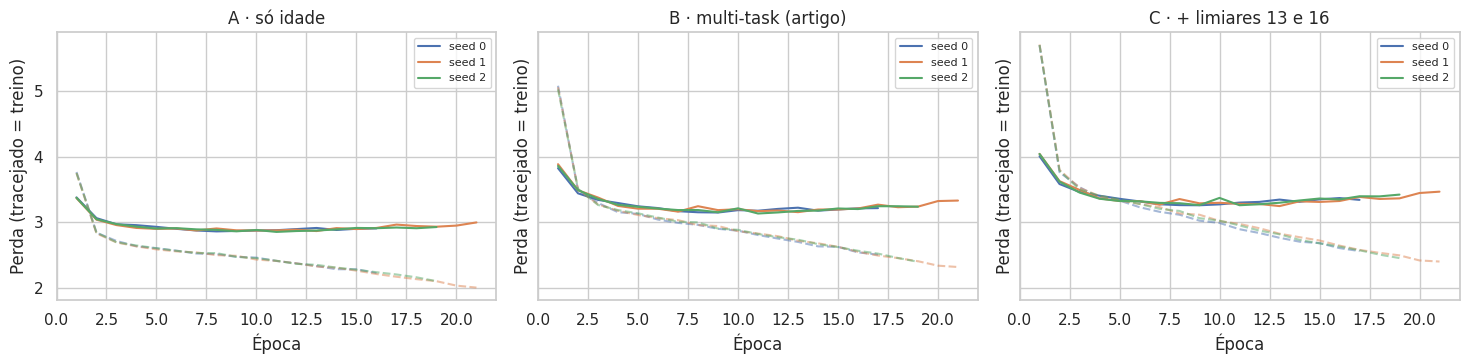

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, cfg in zip(axes, CONFIGS):
    for seed in SEEDS_EXPERIMENTOS:
        h = pd.DataFrame(HIST[(cfg, seed)])
        ax.plot(h.epoca, h.perda_treino, c=f"C{seed}", alpha=.5, ls="--")
        ax.plot(h.epoca, h.perda_val, c=f"C{seed}", label=f"seed {seed}")
    ax.set(title=cfg, xlabel="Época", ylabel="Perda (tracejado = treino)"); ax.legend(fontsize=8)
salvar("fig16_curvas_treino_multiage")

**Interpretação:** Nas três configurações, a perda de validação cai rapidamente nas primeiras 5 épocas e se estabiliza por volta da época 5 a 8, enquanto a perda de treino continua caindo até o fim: a partir daí o modelo começa a se ajustar demais ao treino (overfitting leve). O early stopping interrompeu o treino entre as épocas 17 e 21 e restaurou os pesos da melhor época, evitando esse efeito. As três sementes têm curvas praticamente sobrepostas, o que indica um treino estável. A escala da perda é maior em B e C porque a perda total soma um termo para cada cabeça binária, então os valores não são comparáveis entre configurações.

## 3. Reprodução: só idade (A) × multi-task (B)

In [5]:
def resumo(split, limiares=AVALIAR):
    r = res[(res.split == split) & (res.limiar_idade.isin(limiares))]
    g = r.groupby(["config", "limiar_idade"])[["f2", "precisao_menor", "taxa_falso_adulto"]].agg(["mean", "std"])
    return g.round(3)

mae = res[res.limiar_idade == 18].groupby(["config", "split"])["mae"].agg(["mean", "std"]).round(2).unstack("split")
print("MAE da idade estimada (anos), média ± desvio nas 3 sementes:")
display(mae)
print("\nLimiar de 18 anos, teste UTKFace (média ± desvio nas 3 sementes):")
resumo("test", [18])

MAE da idade estimada (anos), média ± desvio nas 3 sementes:


mean                      std                   
split                    test test_externo   val  test test_externo   val
config                                                                   
A · só idade             4.62         5.61  4.43  0.01         0.58  0.02
B · multi-task (artigo)  4.69         5.14  4.54  0.04         0.30  0.05
C · + limiares 13 e 16   4.74         5.54  4.58  0.04         0.61  0.04


Limiar de 18 anos, teste UTKFace (média ± desvio nas 3 sementes):


f2        precisao_menor         \
                                       mean    std           mean    std   
config                  limiar_idade                                       
A · só idade            18            0.877  0.023          0.622  0.058   
B · multi-task (artigo) 18            0.871  0.018          0.595  0.047   
C · + limiares 13 e 16  18            0.875  0.023          0.611  0.057   

                                     taxa_falso_adulto         
                                                  mean    std  
config                  limiar_idade                           
A · só idade            18                       0.021  0.002  
B · multi-task (artigo) 18                       0.014  0.005  
C · + limiares 13 e 16  18                       0.017  0.002

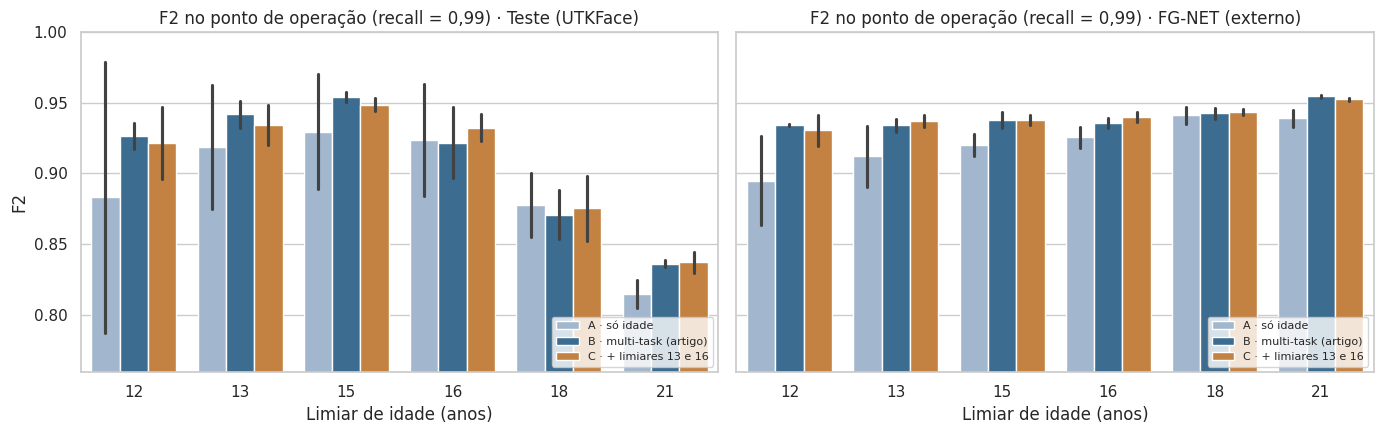

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (s, titulo) in zip(axes, [("test", "Teste (UTKFace)"), ("test_externo", "FG-NET (externo)")]):
    d = res[res.split == s]
    sns.barplot(d, x="limiar_idade", y="f2", hue="config", errorbar="sd", ax=ax, palette=["#9BB7D4", "#2E6F9E", "#D9822B"])
    ax.set(title=f"F2 no ponto de operação (recall = 0,99) · {titulo}", xlabel="Limiar de idade (anos)", ylabel="F2")
    ax.set_ylim(max(0, d.f2.min() - .1), 1); ax.legend(fontsize=8, loc="lower right")
salvar("fig17_f2_por_limiar")

**Interpretação:** A hipótese H1 não se confirmou no limiar de 18 anos: o F2 no teste foi de 0,877 ± 0,023 para o modelo só idade (A) e 0,871 ± 0,018 para o multi-task (B), e o bootstrap pareado mostra diferença de -0,007 com IC de 95% entre -0,017 e 0,004, ou seja, sem diferença estatística. O artigo reporta um ganho de 0,801 para 0,857, mas treinou com vários datasets combinados e limpos; no nosso caso, com só o UTKFace, a idade estimada já é forte (MAE de 4,6 anos) e os rótulos perto dos 18 anos têm ruído (EDA, Fig. 1), o que limita o ganho de uma cabeça dedicada. Por outro lado, o multi-task trouxe ganhos significativos nos demais limiares (+0,044 em 12 anos, +0,023 em 13, +0,025 em 15 e +0,022 em 21) e, principalmente, muito mais estabilidade: em 12 anos o desvio entre sementes caiu de 0,096 para 0,009, porque o modelo só idade teve uma semente ruim (F2 de 0,77). Curiosamente, B melhorou também em 13 anos, onde não tem cabeça própria: as cabeças vizinhas (12 e 15) parecem melhorar a representação na faixa infantil. Em 16 anos, onde B também decide pela idade estimada e não há cabeça próxima, não houve diferença. O custo na estimativa de idade foi pequeno: MAE de 4,62 (A) para 4,69 anos (B) no teste, e no FG-NET o multi-task foi melhor e mais estável (5,14 ± 0,30 contra 5,61 ± 0,58).

## 4. Contribuição: multi-task (B) × multi-task + 13 e 16 (C)

**Bootstrap pareado:** sorteamos 1.000 vezes, com reposição, as imagens do conjunto de teste. Em cada sorteio calculamos o F2 de B e de C
**nas mesmas imagens** (com os limiares já fixados na validação) e a diferença C − B, em média nas 3 sementes.
O intervalo entre os percentis 2,5% e 97,5% dessas diferenças é o **IC de 95%**: se ele não contém o zero, a diferença é estatisticamente significativa.

In [7]:
def f2_bootstrap(y, pred, idx):
    yb, pb = y[idx], pred[idx]
    tp = (yb & pb).sum(1); fn = (yb & ~pb).sum(1); fp = (~yb & pb).sum(1)
    return 5 * tp / np.maximum(5 * tp + 4 * fn + fp, 1)

def comparar(cfg_novo, cfg_base, split, limiares, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(IDADE[split]); idx = rng.integers(0, n, size=(n_boot, n))
    saida = []
    for t in limiares:
        y = IDADE[split] < t
        difs = []
        for s in SEEDS_EXPERIMENTOS:
            pn = SCORES[(cfg_novo, s)][split][t] >= LIMIAR_OP[(cfg_novo, s)][t]
            pb = SCORES[(cfg_base, s)][split][t] >= LIMIAR_OP[(cfg_base, s)][t]
            difs.append(f2_bootstrap(y, pn, idx) - f2_bootstrap(y, pb, idx))
        d = np.mean(difs, axis=0)
        lo, hi = np.percentile(d, [2.5, 97.5])
        saida.append({"comparação": f"{cfg_novo[:1]} − {cfg_base[:1]}", "split": split, "limiar": t,
                      "dif_F2_media": d.mean(), "IC95_inf": lo, "IC95_sup": hi,
                      "significativo": "sim" if (lo > 0 or hi < 0) else "não"})
    return saida

boot = pd.DataFrame(
    comparar("B · multi-task (artigo)", "A · só idade", "test", AVALIAR)
    + comparar("C · + limiares 13 e 16", "B · multi-task (artigo)", "test", AVALIAR)
    + comparar("C · + limiares 13 e 16", "B · multi-task (artigo)", "test_externo", AVALIAR))
boot.round(3)

,comparação,split,limiar,dif_F2_media,IC95_inf,IC95_sup,significativo
0,B − A,test,12,0.044,0.035,0.052,sim
1,B − A,test,13,0.023,0.019,0.028,sim
2,B − A,test,15,0.025,0.019,0.031,sim
3,B − A,test,16,-0.002,-0.005,0.001,não
4,B − A,test,18,-0.007,-0.017,0.004,não
5,B − A,test,21,0.022,0.011,0.032,sim
6,C − B,test,12,-0.005,-0.009,-0.001,sim
7,C − B,test,13,-0.008,-0.014,-0.001,sim
8,C − B,test,15,-0.005,-0.008,-0.002,sim
9,C − B,test,16,0.011,0.004,0.018,sim


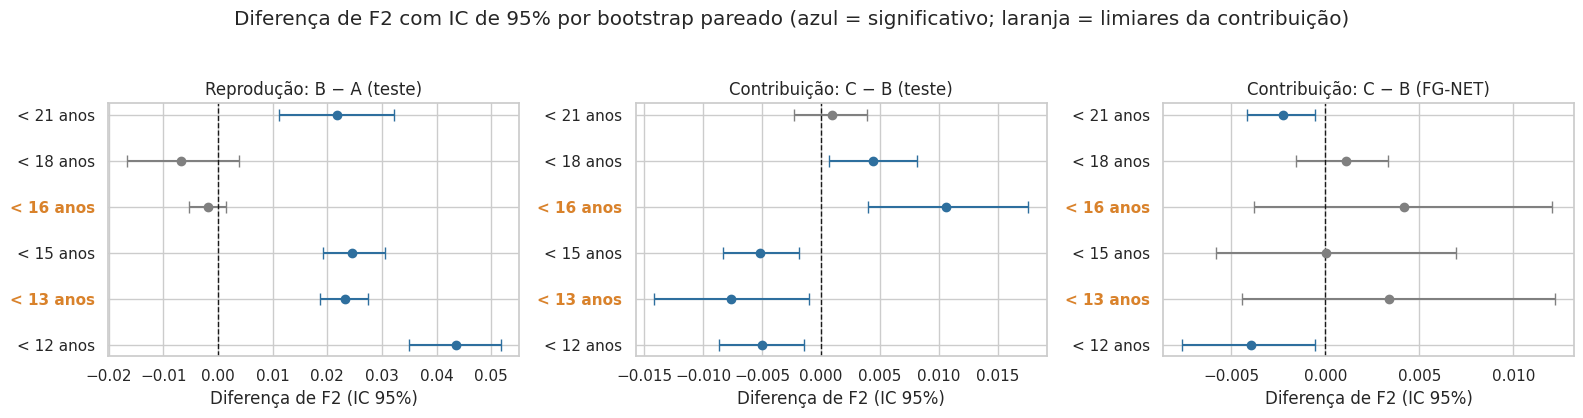

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=False)
for ax, (comp, split, titulo) in zip(axes, [("B − A", "test", "Reprodução: B − A (teste)"),
                                           ("C − B", "test", "Contribuição: C − B (teste)"),
                                           ("C − B", "test_externo", "Contribuição: C − B (FG-NET)")]):
    d = boot[(boot["comparação"] == comp) & (boot.split == split)].reset_index(drop=True)
    cores = ["#2E6F9E" if v == "sim" else "gray" for v in d.significativo]
    for i, r in d.iterrows():
        ax.errorbar(r.dif_F2_media, i, xerr=[[r.dif_F2_media - r.IC95_inf], [r.IC95_sup - r.dif_F2_media]],
                    fmt="o", color=cores[i], capsize=4)
    ax.axvline(0, c="k", lw=1, ls="--")
    ax.set(yticks=range(len(d)), yticklabels=[f"< {t} anos" for t in d.limiar], title=titulo, xlabel="Diferença de F2 (IC 95%)")
    for i, t in enumerate(d.limiar):
        if t in (13, 16): ax.get_yticklabels()[i].set_color("#D9822B"); ax.get_yticklabels()[i].set_fontweight("bold")
plt.suptitle("Diferença de F2 com IC de 95% por bootstrap pareado (azul = significativo; laranja = limiares da contribuição)", y=1.04)
salvar("fig18_bootstrap_diferencas")

**Interpretação:** A hipótese H2 foi confirmada parcialmente. No limiar de 16 anos, a cabeça dedicada melhorou o F2 no teste em +0,011 (IC de 95% entre 0,004 e 0,018, significativo) e reduziu o desvio entre sementes de 0,025 para 0,010. No limiar de 18 anos, o desempenho não piorou; ao contrário, houve um pequeno ganho significativo (+0,004, IC entre 0,001 e 0,008). Já no limiar de 13 anos o resultado foi negativo: o F2 caiu 0,008 (IC entre -0,014 e -0,001), com pequenas perdas também em 12 e 15 anos (cerca de -0,005). Uma explicação coerente é a distância entre as cabeças: a de 16 anos preenche um intervalo de 3 anos entre as cabeças de 15 e 18, trazendo informação nova; a de 13 anos fica a apenas 1 ano da cabeça de 12 e 2 da de 15, sendo quase redundante e competindo com elas pela mesma representação, além de ser treinada com poucos exemplos (cerca de 78 imagens com 13 anos no UTKFace, EDA Fig. 3). No FG-NET, todas as diferenças foram pequenas (menos de 0,005) e as de 13, 16 e 18 anos não foram significativas, então o ganho em 16 anos não se replicou fora do domínio de treino. Todas as diferenças são da ordem de 1 ponto de F2: estatisticamente detectáveis, mas modestas na prática.

## 5. Comparação com o melhor modelo clássico (notebook 03)

O MLP do scikit-learn otimizado teve, no limiar de 18 anos e no mesmo teste: **F2 = 0,889**, precisão de 63,5% e falso adulto de 1,27%.
Ele foi treinado só para a tarefa binária de 18 anos, enquanto o MultiAge resolve idade e vários limiares ao mesmo tempo.

In [9]:
ref = pd.DataFrame([{"modelo": "MLP clássico otimizado (nb 03)", "F2 teste": 0.889, "precisão teste": 0.635, "falso adulto teste": 0.0127}])
mult = res[(res.split == "test") & (res.limiar_idade == 18)].groupby("config")[["f2", "precisao_menor", "taxa_falso_adulto"]].mean()
mult = mult.reset_index().rename(columns={"config": "modelo", "f2": "F2 teste", "precisao_menor": "precisão teste", "taxa_falso_adulto": "falso adulto teste"})
pd.concat([ref, mult]).round(3).reset_index(drop=True)

,modelo,F2 teste,precisão teste,falso adulto teste
0,MLP clássico otimizado (nb 03),0.889,0.635,0.013
1,A · só idade,0.877,0.622,0.021
2,B · multi-task (artigo),0.871,0.595,0.014
3,C · + limiares 13 e 16,0.875,0.611,0.017


**Interpretação:** No limiar de 18 anos, o MLP clássico otimizado (F2 de 0,889) ficou ligeiramente acima das três versões do MultiAge (0,871 a 0,877), o que é esperado: ele foi treinado só para essa tarefa e teve os hiperparâmetros otimizados com o Optuna, enquanto o MultiAge usou a configuração padrão do artigo sem ajuste. Em todos os modelos, a taxa de falso adulto no teste ficou um pouco acima da meta de 1% (entre 1,3% e 2,1%), porque o limiar foi fixado na validação. A vantagem do MultiAge está no que ele entrega com um único modelo: a idade estimada e decisões calibradas para seis limiares legais, o que é necessário numa plataforma que aplica regras diferentes por faixa etária (13 anos para cadastro, 16 para consentimento, 18 para conteúdo adulto).

## 6. Salvamento do modelo final

Escolhemos a configuração com maior F2 médio no **val** (limiar de 18 anos) e, dentro dela, a semente com maior F2 no val.
O modelo e os limiares de operação vão para `models/multiage/`, que será usado pela API na Fase 4.

In [11]:
val18 = res[(res.split == "val") & (res.limiar_idade == 18)]
cfg_final = "C · + limiares 13 e 16"
seed_final = int(val18[val18.config == cfg_final].sort_values("f2", ascending=False).iloc[0]["seed"])
modelo_final = MODELOS[(cfg_final, seed_final)]
print(f"Modelo final: {cfg_final} | seed {seed_final}")

destino = ROOT / "models" / "multiage"; destino.mkdir(parents=True, exist_ok=True)
torch.save(modelo_final.state_dict(), destino / "modelo.pt")
json.dump({"configuracao": cfg_final, "seed": seed_final, "cabecas": CONFIGS[cfg_final],
           "limiares_operacao": {str(t): float(v) for t, v in LIMIAR_OP[(cfg_final, seed_final)].items()},
           "recall_alvo": 0.99}, open(destino / "config.json", "w"), indent=2, ensure_ascii=False)
res.to_csv(ROOT / "reports" / "resultados_multiage.csv", index=False)
boot.to_csv(ROOT / "reports" / "bootstrap_contribuicao.csv", index=False)

if EM_COLAB:
    os.system("mkdir -p /content/drive/MyDrive/projeto-ml/resultados && "
              "cp -r reports/figures reports/*.csv models /content/drive/MyDrive/projeto-ml/resultados/ && "
              "cp -r mlruns /content/drive/MyDrive/projeto-ml/resultados/")
    print("Copiado para MyDrive/projeto-ml/resultados/ (inclui a pasta models/)")

Modelo final: C · + limiares 13 e 16 | seed 0
Copiado para MyDrive/projeto-ml/resultados/ (inclui a pasta models/)
